# 01. Разведочный анализ данных (EDA)

**Проект:** прогноз дневных продаж розничных банковских продуктов (карты, кредиты, срочные депозиты) на 4 недели вперёд.

**Проблема.** Планы продаж для отделений и онлайн-каналов, потребность в фондировании (сколько денег уйдёт на кредиты и придёт с депозитов) и нагрузку на персонал сейчас планируют вручную, по прошлым месяцам. Ручной план не учитывает праздники, длинные выходные, эффект понедельника и тренды отдельных продуктов.

**Пользователь.** Аналитик / менеджер по продажам розничного блока банка: раз в 4 недели получает прогноз продаж по каждому продукту на ближайшие 28 дней.

**ML-задача.** Регрессия на временных рядах: по истории ряда и календарю предсказать число продаж (новых договоров) в каждый из 28 следующих дней. Целевая переменная `y` — число продаж за день в ряду.

**Что в этом ноутбуке:** обзор данных → проверка качества (пропуски, дубликаты, аномалии) → структура продаж → сезонность (неделя, месяц, праздники) → структурные сдвиги и выбросы → корреляции и автокорреляции → выводы и решения для модели.

## 0. Источник данных

Данные — выгрузка из хранилища банка (витрины карт, кредитов и депозитов, MS SQL) за период **01.01.2023 – 30.09.2026** по дням. SQL-скрипты выгрузки лежат в папке `sql/`.

**Важно: в репозитории лежит обезличенная версия данных.** Каждый ряд умножен на свой секретный коэффициент, поэтому абсолютные объёмы не совпадают с реальными. Даты, нулевые дни, недельный профиль, праздники и всплески сохранены, так что все закономерности и выводы остаются теми же. Все числа в этом ноутбуке посчитаны на обезличенных данных.

Почему этот источник:
* это те продажи, которые банк действительно планирует, — задача реальная, а не учебная;
* 3,75 года дневной истории — три полных годовых цикла, видна годовая сезонность;
* данных достаточно: 15 рядов × ~1 300 дней ≈ 18–19 тыс. наблюдений.

**Подготовка в SQL** (подробнее — в README): каждый договор берётся один раз, из среза витрины за месяц открытия (в витринах договор повторяется каждый месяц, пока активен); исключены продукты сотрудников, тестовые и дополнительные карты, депозиты на индивидуальных условиях; сотни карточных продуктов и десятки кредитных и депозитных сгруппированы в 16 рядов. Дни без продаж выгружены с нулём.

**Ограничения:** один банк и одна страна; продукты банка менялись со временем (см. раздел о смене продуктов).

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as C
from src.data import load_series, series_info
from src.calendar_kg import days_off, EXTRA_DAYS_OFF
from src.plotting import setup, month_axis, save
setup()
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

raw = pd.read_csv(C.DATA, parse_dates=['date'])   # реальные данные, если есть, иначе обезличенные
print('Файл данных:', C.DATA.name)
raw.head()

Файл данных: sales_series_daily_masked.csv


,date,product_group,series_group,credit_supply_limit,sales_count,cards_count,sales_amount,closures_count,early_closures
0,2023-01-01,Депозит,Архивные (только закрытия),0,0,NaN,0.0,0.0,0.0
1,2023-01-02,Депозит,Архивные (только закрытия),0,0,NaN,0.0,0.0,0.0
2,2023-01-03,Депозит,Архивные (только закрытия),0,0,NaN,0.0,0.0,0.0
3,2023-01-04,Депозит,Архивные (только закрытия),0,0,NaN,0.0,0.0,0.0
4,2023-01-05,Депозит,Архивные (только закрытия),0,0,NaN,0.0,0.0,0.0


## 1. Обзор данных: размер, типы, признаки

Одна строка — **день × ряд продаж**. Колонки:

| колонка | что это |
|---|---|
| `date` | дата |
| `product_group` | группа продукта: Карта / Кредит / Депозит |
| `series_group` | ряд прогноза внутри группы (например, «Онлайн кредит») |
| `credit_supply_limit` | 1 — банк ограничивал выдачи кредитов из-за нехватки ресурсов |
| `sales_count` | **целевая переменная**: число продаж (новых договоров) за день |
| `cards_count` | выпущенные карты по новым договорам (только карты) |
| `sales_amount` | сумма выдач / открытий (кредиты, депозиты) |
| `closures_count`, `early_closures` | погашения / закрытия и из них досрочные |

Прогнозируем `sales_count`. Суммы и закрытия использую только для анализа: их будущие значения на 4 недели вперёд неизвестны. Ставки и сроки продуктов в публичную версию не включены.

In [2]:
print('Размер:', raw.shape)
print('Период:', raw.date.min().date(), '—', raw.date.max().date(), '| дней:', raw.date.nunique())
print('\nТипы колонок:'); print(raw.dtypes)
print('\nРядов по группам:'); print(raw.groupby('product_group').series_group.nunique())

Размер: (21904, 9)
Период: 2023-01-01 — 2026-09-30 | дней: 1369

Типы колонок:
date                   datetime64[us]
product_group                     str
series_group                      str
credit_supply_limit             int64
sales_count                     int64
cards_count                   float64
sales_amount                  float64
closures_count                float64
early_closures                float64
dtype: object

Рядов по группам:
product_group
Депозит    5
Карта      7
Кредит     4
Name: series_group, dtype: int64


## 2. Качество данных: пропуски, дубликаты, полнота календаря, некорректные значения

In [3]:
key = ['date', 'product_group', 'series_group']
print('Дубликатов по ключу день × ряд:', raw.duplicated(key).sum())
print('Отрицательных продаж:', (raw.sales_count < 0).sum())
# Полнота: в каждом ряду должны быть все дни периода
full = raw.groupby(['product_group', 'series_group']).date.nunique()
print('Все ряды содержат все', raw.date.nunique(), 'дней:', (full == raw.date.nunique()).all())
print('\nПропуски по колонкам (доля):')
print(raw.isna().mean().round(3))

Дубликатов по ключу день × ряд: 0
Отрицательных продаж: 0
Все ряды содержат все 1369 дней: True

Пропуски по колонкам (доля):
date                   0.000
product_group          0.000
series_group           0.000
credit_supply_limit    0.000
sales_count            0.000
cards_count            0.562
sales_amount           0.438
closures_count         0.438
early_closures         0.438
dtype: float64


**Что видим и что делаем:**
* дубликатов и отрицательных значений нет, календарь полный — дни без продаж выгружены нулями (это важно: пропущенный день модель бы «не увидела»);
* пропуски есть только в `cards_count` (у кредитов и депозитов нет карт) и в `sales_amount` / `closures_*` (у карт нет сумм и погашений) — **это не ошибки**, а величины, которые для этой группы не определены. В модель эти колонки не идут;
* у целевой переменной `sales_count` пропусков нет.

In [4]:
df = load_series()          # ряды для модели: без «Архивных» депозитов, начало ряда — с первой продажи
info = series_info(df)
info.assign(zero_share=(info.zero_share * 100).round(0).astype(int).astype(str) + ' %').round(1)

start        end  days      total  mean_per_day zero_share
product_group series                                                                                                            
Карта         Карта: Visa/MC массовые (именные + предвыпущенные) 2023-01-09 2026-09-30  1361  1164927.0         855.9       32 %
              Карта: Зарплатные                                  2023-01-09 2026-09-30  1361   254358.0         186.9       32 %
              Карта: Виртуальные                                 2023-01-10 2026-09-30  1360   185694.0         136.5       33 %
              Карта: Нерезиденты                                 2023-01-09 2026-09-30  1361   153960.0         113.1       32 %
Кредит        Кредит: Экспресс и кредит наличными                2023-01-09 2026-09-30  1361   114038.0          83.8       35 %
              Кредит: Онлайн кредит                              2023-01-09 2026-09-30  1361    98119.0          72.1       45 %
              Кредит: Товарный кредит / рассрочка                2023-01-09 2026-09-30  1361    71021.0          52.2       37 %
Депозит       Депозит: Онлайн-вклады                             2023-01-09 2026-09-30  1361    60681.0          44.6       33 %
Карта         Карта: Элкарт пенс/соц                             2023-01-09 2026-09-30  1361    32490.0          23.9       33 %
              Карта: Элкарт розница                              2023-01-09 2026-09-30  1361    32260.0          23.7       32 %
Депозит       Депозит: Копилка (онлайн)                          2025-05-12 2026-09-30   507    25962.0          51.2       32 %
Карта         Карта: Кредитные / рассрочка                       2023-01-09 2026-09-30  1361    17686.0          13.0       43 %
Депозит       Депозит: Классические срочные                      2023-01-09 2026-09-30  1361     7307.0           5.4       33 %
              Депозит: Пенсионные                                2023-01-09 2026-09-30  1361     7305.0           5.4       33 %
Кредит        Кредит: Ипотека, авто и прочие                     2023-01-12 2026-09-30  1358     1085.0           0.8       62 %

**Комментарий.** 15 рядов сильно различаются по масштабу: от ~0,8 продажи в день («Ипотека, авто и прочие») до ~860 («Visa/MC массовые»). Нулевых дней 32–45 % (у ипотеки 62 %): это выходные и праздники, а у онлайн-кредита и кредитных карт ещё и периоды, когда продукта почти не было. Отсюда два решения:
1. метрика должна быть устойчива к нулям и к масштабу — беру **WAPE** (а не MAPE, которая делит на ноль);
2. для моделей использую лог-преобразование цели или функции потерь для счётных данных (Poisson / Tweedie).

«Архивные» депозиты исключены: продаж в них нет, только закрытия. Копилка начинается с 12.05.2025 — дни до запуска продукта отрезаны, это не «нулевой спрос».

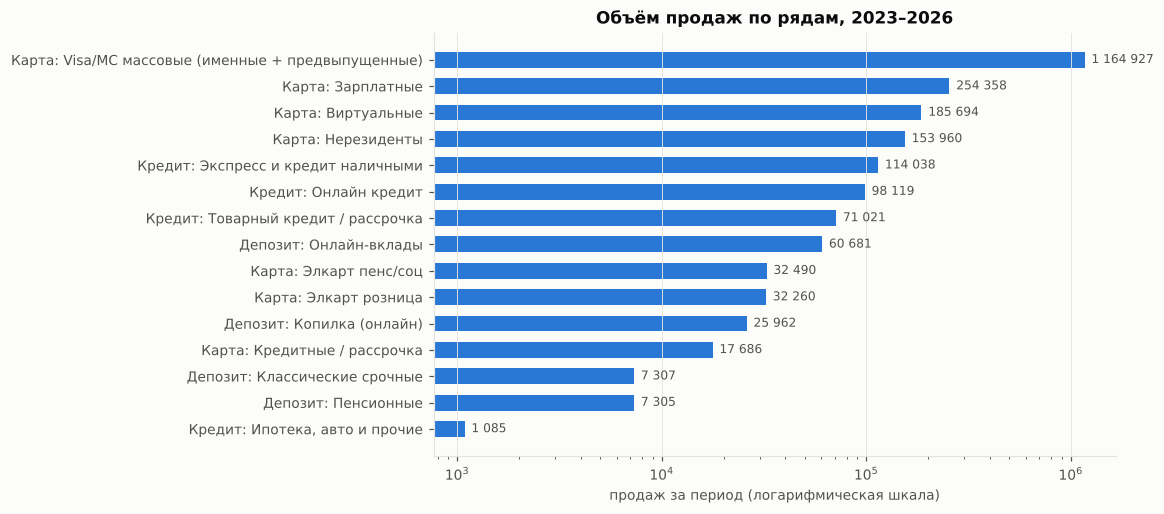

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
s = info.reset_index().sort_values('total')
ax.barh(s.series, s.total, color=C.COLORS['s1'], height=0.6)
ax.set_xscale('log'); ax.set_xlabel('продаж за период (логарифмическая шкала)')
ax.set_title('Объём продаж по рядам, 2023–2026')
for i, v in enumerate(s.total):
    ax.text(v * 1.08, i, f'{v:,.0f}'.replace(',', ' '), va='center', fontsize=8, color=C.COLORS['muted'])
ax.grid(axis='y', visible=False)
save(fig, 'eda_volume_by_series'); plt.show()

## 3. Динамика по месяцам: тренды и структурные сдвиги

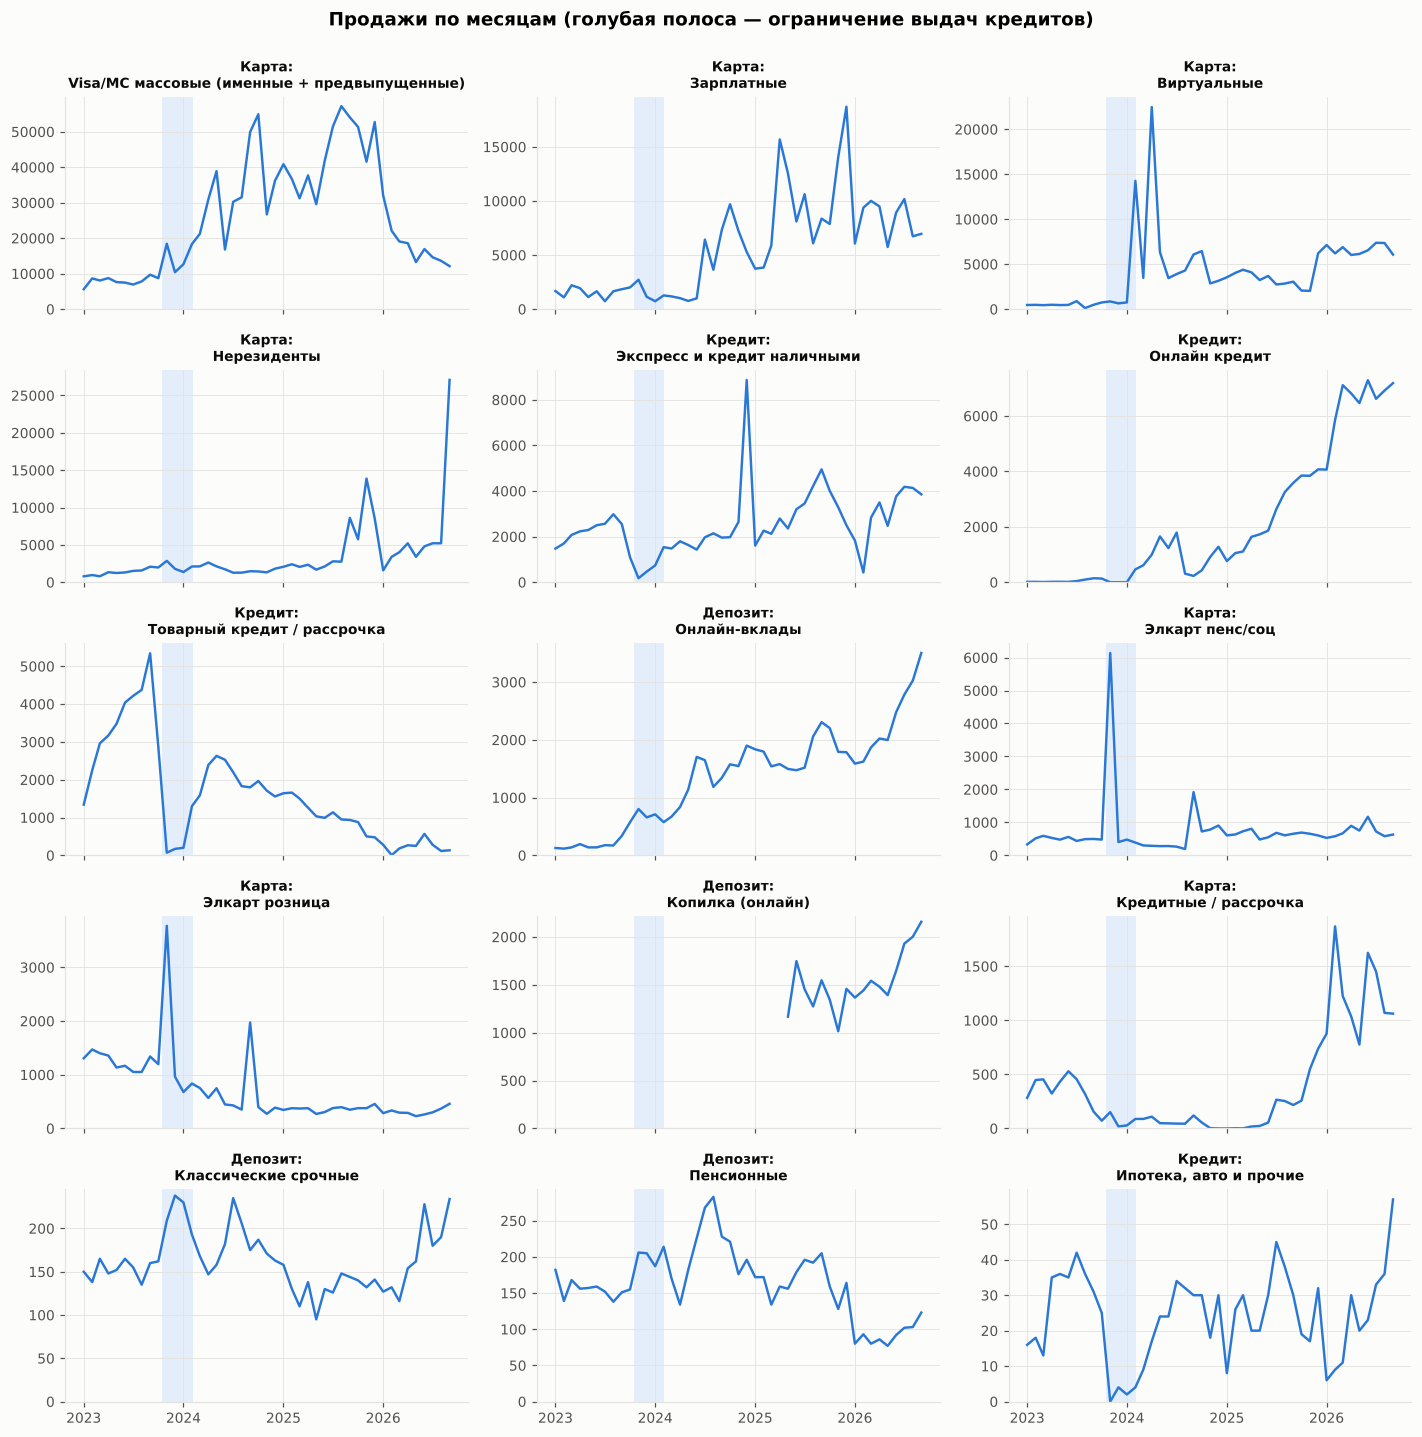

In [6]:
m = df.groupby(['series', pd.Grouper(key='date', freq='MS')]).y.sum().reset_index()
series = info.reset_index().series.tolist()
fig, axes = plt.subplots(5, 3, figsize=(13, 13), sharex=True)
for ax, s in zip(axes.flat, series):
    d = m[m.series == s]
    ax.plot(d.date, d.y, color=C.COLORS['s1'])
    ax.set_title(s.replace(': ', ':\n'), fontsize=9)
    ax.set_ylim(bottom=0); month_axis(ax, yearly=True)
    ax.axvspan(pd.Timestamp(C.CREDIT_LIMIT_START), pd.Timestamp(C.CREDIT_LIMIT_END), color=C.COLORS['band'], alpha=0.5, lw=0)
fig.suptitle('Продажи по месяцам (голубая полоса — ограничение выдач кредитов)', y=1.0, fontsize=12, fontweight='bold')
fig.tight_layout(); save(fig, 'eda_monthly_small_multiples'); plt.show()

**Что видно:**
* **Онлайн кредит, онлайн-вклады, копилка, виртуальные карты** быстро растут — сильный тренд, банк уходит в онлайн;
* **Товарный кредит** почти исчез к 2026 г. (продукт сворачивается), **Visa/MC массовые** падают в 2026 г. — для модели это нестационарность: прогноз «как в прошлом году» здесь не работает, нужны признаки недавнего уровня и тренда;
* видны разовые всплески (нерезиденты 09.2026, Элкарт пенс/соц 11.2023) — разбираем ниже.

### Смена продуктов внутри рядов
Некоторые ряды объединены на этапе подготовки, потому что банк **заменил один продукт другим**. Покажем, зачем это было нужно: без объединения ряды «обрываются», и модель приняла бы смену продукта за падение спроса.

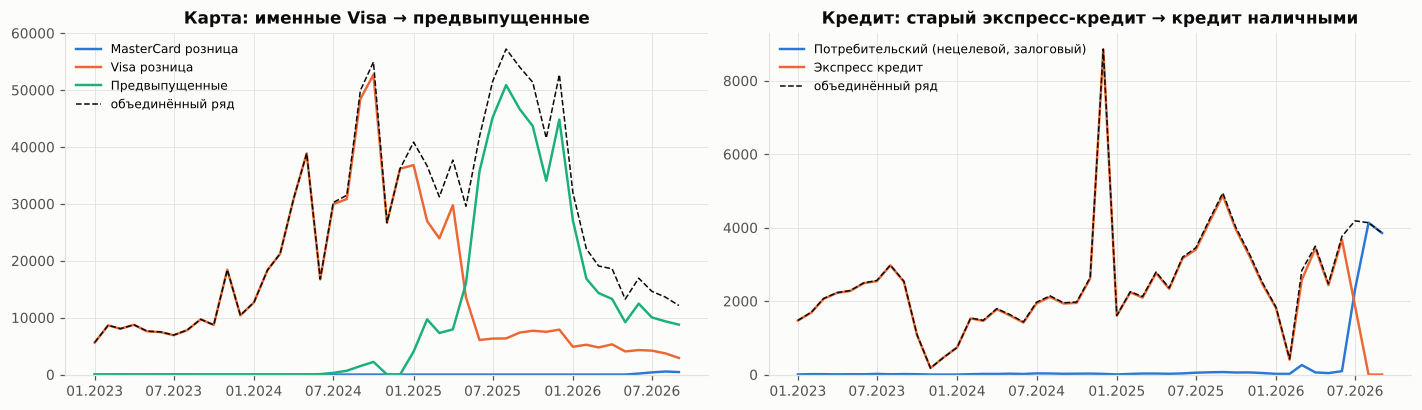

In [7]:
ch = pd.read_csv(C.DATA_BYCH, parse_dates=['date'])
cases = [('Visa/MC массовые (именные + предвыпущенные)', 'Карта: именные Visa → предвыпущенные'),
         ('Экспресс и кредит наличными', 'Кредит: старый экспресс-кредит → кредит наличными')]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (sg, title) in zip(axes, cases):
    d = ch[ch.series_group == sg].groupby(['subgroup', pd.Grouper(key='date', freq='MS')]).sales_count.sum().reset_index()
    for color, (sub, g) in zip([C.COLORS['s1'], C.COLORS['s2'], C.COLORS['s3']], d.groupby('subgroup')):
        ax.plot(g.date, g.sales_count, color=color, label=sub)
    tot = d.groupby('date').sales_count.sum()
    ax.plot(tot.index, tot.values, color=C.COLORS['actual'], lw=1, ls='--', label='объединённый ряд')
    ax.set_title(title); ax.legend(fontsize=8); ax.set_ylim(bottom=0); month_axis(ax)
fig.tight_layout(); save(fig, 'eda_product_switch'); plt.show()

**Вывод.** Именные Visa с 2025 г. зеркально заменяются предвыпущенными картами (дата открытия предвыпущенной карты — это выдача клиенту, то есть продажа); старый экспресс-кредит в 2026 г. заменён кредитом наличными. Объединённые ряды непрерывны — их и прогнозирую.

## 4. Аномальный период: ограничение выдач кредитов

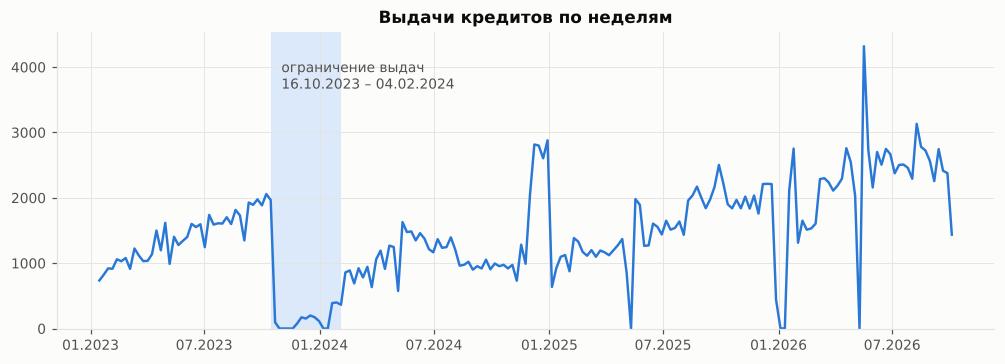

Средние выдачи в неделю: до — 1848 | во время — 133


In [8]:
k = df[df.product_group == 'Кредит'].groupby(pd.Grouper(key='date', freq='W')).y.sum()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(k.index, k.values, color=C.COLORS['s1'])
ax.axvspan(pd.Timestamp(C.CREDIT_LIMIT_START), pd.Timestamp(C.CREDIT_LIMIT_END), color=C.COLORS['band'], alpha=0.7, lw=0)
ax.text(pd.Timestamp('2023-11-01'), k.max() * 0.85, 'ограничение выдач\n16.10.2023 – 04.02.2024', fontsize=9, color=C.COLORS['muted'])
ax.set_title('Выдачи кредитов по неделям'); ax.set_ylim(bottom=0); month_axis(ax)
save(fig, 'eda_credit_limit'); plt.show()
print('Средние выдачи в неделю: до —', int(k[:C.CREDIT_LIMIT_START][-8:].mean()),
      '| во время —', int(k[C.CREDIT_LIMIT_START:C.CREDIT_LIMIT_END].mean()))

С 16.10.2023 по 04.02.2024 банк ограничивал выдачи из-за нехватки ресурсов — **это ограничение предложения, а не падение спроса**. Удалять период нельзя (сломаются лаги и непрерывность рядов), оставлять «как есть» — модель решит, что зимой спрос падает в 10 раз. Решение:
* признак `credit_supply_limit` = 1 в этот период (модель учится, что при ограничении продаж почти нет);
* признак `limit_share_lag_window` — доля дней ограничения в окне, из которого взяты лаги (после снятия ограничения лаги ещё «помнят» провал);
* в прогнозе на будущее флаг = 0 (в демо его можно включить как сценарий), а качество на этом периоде не оцениваем.

## 5. Недельная сезонность

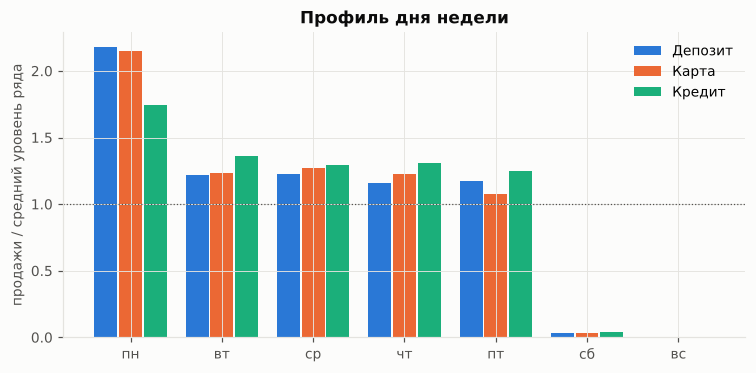

product_group,Депозит,Карта,Кредит
dow,,,
0,2.18,2.15,1.74
1,1.22,1.24,1.36
2,1.22,1.27,1.30
3,1.16,1.22,1.31
4,1.17,1.08,1.25
5,0.03,0.03,0.04
6,0.00,0.00,0.00


In [9]:
d = df.copy(); d['dow'] = d.date.dt.dayofweek
# нормируем на средний уровень ряда, чтобы ряды разного масштаба были сравнимы
d['rel'] = d.y / d.groupby('series').y.transform('mean')
w = d.groupby(['product_group', 'dow']).rel.mean().unstack(0)
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(7); width = 0.27
for i, (pg, color) in enumerate(zip(w.columns, [C.COLORS['s1'], C.COLORS['s2'], C.COLORS['s3']])):
    ax.bar(x + (i - 1) * width, w[pg], width=width - 0.02, color=color, label=pg)
ax.set_xticks(x, ['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс'])
ax.axhline(1, color=C.COLORS['muted'], lw=0.8, ls=':')
ax.set_ylabel('продажи / средний уровень ряда'); ax.set_title('Профиль дня недели'); ax.legend()
save(fig, 'eda_weekday'); plt.show()
w.round(2)

**Сильнейшая закономерность в данных.** Во всех группах продаж в субботу и воскресенье почти нет, а в понедельник — пик: 1,7× среднего у кредитов и 2,2× у карт и депозитов. Вероятная причина: договор регистрируется в банковской системе в рабочий день, поэтому всё, что клиенты оформили в выходные (в том числе онлайн), попадает на понедельник. Следствия для модели: признаки `dow`, `is_nonwork`, `nonwork_before` (сколько нерабочих дней подряд было перед датой). Бейзлайн должен брать **тот же день недели**: лаг 28 — это ровно 4 недели назад.

## 6. Праздники и длинные выходные

In [10]:
off = days_off()
d['is_holiday'] = d.date.isin(off)
wd = d[d.dow < 5]
hol = wd.groupby(['product_group', 'is_holiday']).rel.mean().unstack()
hol.columns = ['обычный будний день', 'праздник в будний день']
print(hol.round(2))
print('\nНерабочие дни банка, найденные по данным (нет в официальном календаре):', EXTRA_DAYS_OFF)

               обычный будний день  праздник в будний день
product_group                                             
Депозит                       1.49                    0.03
Карта                         1.49                    0.01
Кредит                        1.49                    0.02

Нерабочие дни банка, найденные по данным (нет в официальном календаре): ['2024-11-19', '2024-11-20', '2026-01-08', '2026-01-09', '2026-09-01']


В праздничный будний день продажи падают почти до нуля, как в выходной, а в первый рабочий день после длинных праздников — резкий всплеск (например, 12.01.2026 после новогодних каникул продажи Visa/MC примерно втрое выше обычного рабочего дня). Официальный календарь КР беру из библиотеки `holidays` с переносами выходных и **проверяю по данным**: в каждый праздничный будний день продажи действительно провальные. Дополнительно нашлось 5 будних дней с провалом продаж, которых нет в календаре: 19–20.11.2024, 08–09.01.2026 и 01.09.2026. Я добавил их как нерабочие дни банка. Праздники известны заранее, поэтому их можно использовать в прогнозе без утечки.

## 7. Внутримесячная сезонность (зарплатные дни)

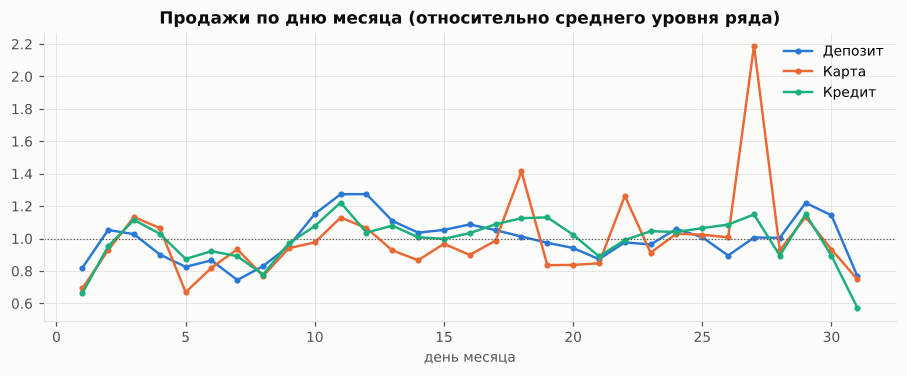

In [11]:
dm = d.groupby(['product_group', d.date.dt.day]).rel.mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 3.4))
for pg, color in zip(dm.columns, [C.COLORS['s1'], C.COLORS['s2'], C.COLORS['s3']]):
    ax.plot(dm.index, dm[pg], color=color, label=pg, marker='o', ms=3)
ax.axhline(1, color=C.COLORS['muted'], lw=0.8, ls=':')
ax.set_xlabel('день месяца'); ax.set_title('Продажи по дню месяца (относительно среднего уровня ряда)'); ax.legend()
save(fig, 'eda_day_of_month'); plt.show()

Выраженного «зарплатного» пика нет, но заметна разница между началом и концом месяца; кроме того, 31-го числа бывает не в каждом месяце, отсюда шум. Признаки `dom` и `days_to_month_end` дадим модели — бустинг сам решит, полезны ли они.

## 8. Распределение целевой переменной и выбросы

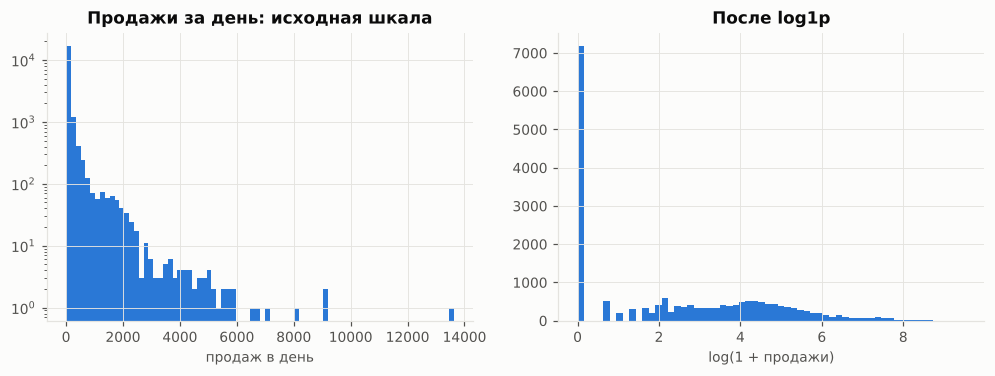

Асимметрия: исходная 9.8 | после log1p 0.38


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(df.y, bins=80, color=C.COLORS['s1']); axes[0].set_yscale('log')
axes[0].set_title('Продажи за день: исходная шкала'); axes[0].set_xlabel('продаж в день')
axes[1].hist(np.log1p(df.y), bins=60, color=C.COLORS['s1'])
axes[1].set_title('После log1p'); axes[1].set_xlabel('log(1 + продажи)')
save(fig, 'eda_target_distribution'); plt.show()
print('Асимметрия: исходная', round(df.y.skew(), 1), '| после log1p', round(np.log1p(df.y).skew(), 2))

Распределение сильно скошено вправо (много нулей и редкие огромные значения). После `log1p` оно гораздо компактнее — поэтому Ridge, RandomForest и CatBoost обучаем на `log1p(y)`, а LightGBM — на `y` с функцией потерь Poisson / Tweedie, предназначенной для счётных данных.

### Поиск выбросов
Выброс = день, когда продажи больше **медианы ряда за ±2 недели × 4** (и больше 50 штук, чтобы не ловить шум в маленьких рядах).

In [13]:
d = df.sort_values(['series', 'date']).copy()
d['med'] = d.groupby('series').y.transform(lambda s: s.rolling(29, center=True, min_periods=7).median())
d['outlier'] = (d.y > 4 * d.med.clip(lower=1)) & (d.y > 50)
out = d[d.outlier].sort_values('y', ascending=False)
print('Найдено дней-выбросов:', len(out), 'из', len(d), f'({len(out)/len(d):.2%})')
out[['date', 'series', 'y', 'med']].head(12)

Найдено дней-выбросов: 325 из 19557 (1.66%)


,date,series,y,med
6359,2024-02-22,Карта: Виртуальные,13616.0,26.0
11370,2026-09-07,Карта: Нерезиденты,9123.0,193.0
5444,2025-05-12,Карта: Visa/MC массовые (именные + предвыпущен...,9021.0,0.0
4912,2023-11-27,Карта: Visa/MC массовые (именные + предвыпущен...,8160.0,518.0
6426,2024-04-29,Карта: Виртуальные,7139.0,379.0
11367,2026-09-04,Карта: Нерезиденты,6735.0,193.0
5689,2026-01-12,Карта: Visa/MC массовые (именные + предвыпущен...,6510.0,0.0
11366,2026-09-03,Карта: Нерезиденты,5818.0,239.0
11716,2023-11-27,Карта: Элкарт пенс/соц,5809.0,12.0
5073,2024-05-06,Карта: Visa/MC массовые (именные + предвыпущен...,5713.0,1268.0


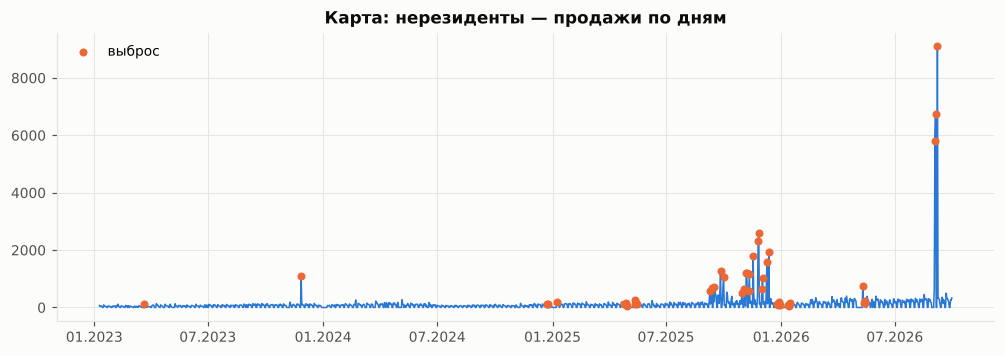

In [14]:
s = d[d.series == 'Карта: Нерезиденты']
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(s.date, s.y, color=C.COLORS['s1'], lw=1)
o = s[s.outlier]
ax.scatter(o.date, o.y, color=C.COLORS['s2'], s=18, zorder=3, label='выброс')
ax.set_title('Карта: нерезиденты — продажи по дням'); ax.legend(); month_axis(ax)
save(fig, 'eda_outliers_nonresidents'); plt.show()

**Решение по выбросам.** Выбросы — это **реальные продажи** (массовый выпуск карт, перевод соцвыплат, акции), а не ошибки данных, поэтому я их **не удаляю и не обрезаю**: бизнесу нужны настоящие объёмы. Но такие события модель по истории предсказать не может (о них заранее знают только организаторы кампании). Поэтому:
* часть «выбросов» — это первый рабочий день после длинных праздников (12.05.2025, 12.01.2026): их модель как раз может предсказать по календарному признаку `nonwork_before`;
* в обучении обычные выбросы оставляю как есть — бустинг устойчив к отдельным выбросам, а скользящие средние за 4–8 недель сглаживают их влияние на признаки;
* в оценке показываю метрики **с событиями и без них**. Крупнейшее событие — массовый выпуск карт нерезидентам 2–8 сентября 2026 г. (за неделю — больше половины продаж ряда за квартал) — попало в тестовый период;
* направление развития — передавать в модель календарь плановых кампаний.

## 9. Автокорреляции: какие лаги полезны

In [15]:
lags = [1, 7, 28, 35, 91, 364]
ac = pd.DataFrame({s: [g.y.autocorr(l) for l in lags] for s, g in df.groupby('series')}, index=[f'лаг {l}' for l in lags]).T
ac.round(2)

,лаг 1,лаг 7,лаг 28,лаг 35,лаг 91,лаг 364
Депозит: Классические срочные,0.20,0.58,0.57,0.56,0.57,0.57
Депозит: Копилка (онлайн),-0.05,0.63,0.68,0.70,0.67,0.69
Депозит: Онлайн-вклады,0.20,0.68,0.70,0.71,0.68,0.68
Депозит: Пенсионные,0.22,0.63,0.62,0.60,0.59,0.57
Карта: Visa/MC массовые (именные + предвыпущенные),0.25,0.78,0.75,0.73,0.67,0.41
Карта: Виртуальные,0.04,0.20,0.10,0.11,0.07,0.04
Карта: Зарплатные,0.42,0.47,0.33,0.33,0.28,0.25
Карта: Кредитные / рассрочка,0.62,0.81,0.66,0.64,0.58,-0.05
Карта: Нерезиденты,0.29,0.10,0.16,0.17,0.14,0.16
Карта: Элкарт пенс/соц,-0.00,0.01,0.01,0.00,0.01,0.04


У большинства рядов сильнее всего лаг 7: тот же день недели неделю назад. Лаги 28 и 35, тоже кратные неделе, остаются высокими. У растущих и сменивших продукт рядов лаг 364 (год назад) слабее. У рядов, где продажи идут волнами кампаний (нерезиденты, Элкарт пенс/соц и розница, виртуальные карты), автокорреляции почти нулевые: прошлое плохо предсказывает будущее, и именно на этих рядах стоит ждать наибольших ошибок модели.

Мы прогнозируем на 28 дней вперёд, поэтому **лаги короче 28 дней использовать нельзя**: в момент прогноза они ещё неизвестны. Берём лаги 28, 35, 42, 49, 56, 63, 91, 182 и 364, а скользящие статистики считаем по окну, которое заканчивается за 28 дней до прогнозируемого дня.

## 10. Корреляции признаков с целевой переменной

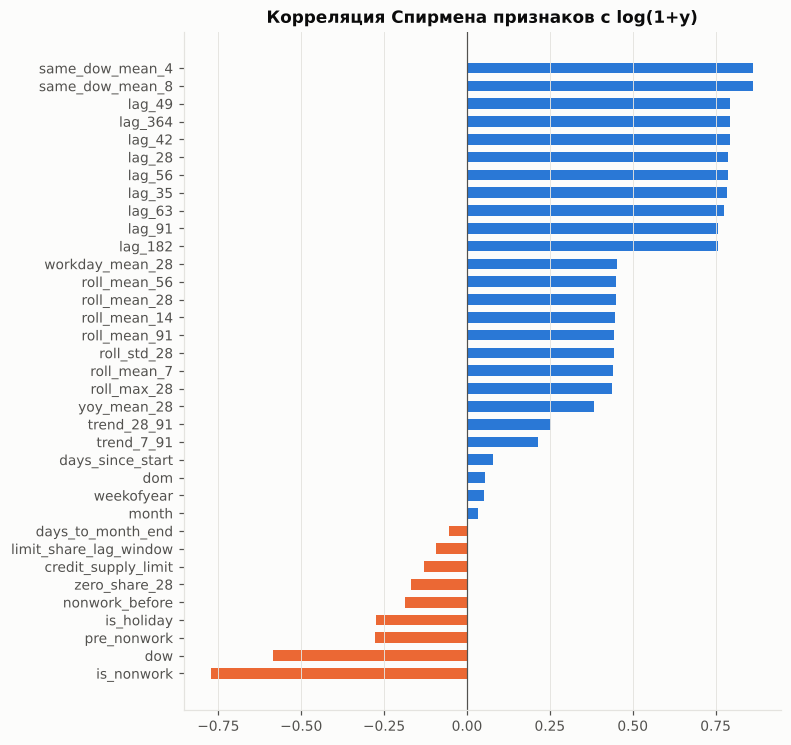

In [16]:
from src.features import build_features, usable_rows
feats = build_features(df); feats = feats[usable_rows(feats)]
num = feats.select_dtypes('number').drop(columns=['y'])
corr = num.corrwith(np.log1p(feats.y), method='spearman').sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(corr.index, corr.values, color=[C.COLORS['s1'] if v > 0 else C.COLORS['s2'] for v in corr.values], height=0.6)
ax.axvline(0, color=C.COLORS['muted'], lw=0.8)
ax.set_title('Корреляция Спирмена признаков с log(1+y)'); ax.grid(axis='y', visible=False)
save(fig, 'eda_feature_correlation'); plt.show()

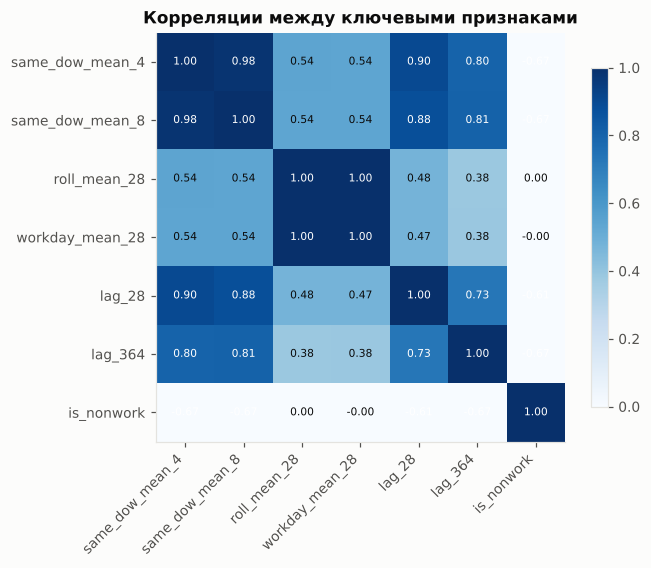

In [17]:
top = ['same_dow_mean_4', 'same_dow_mean_8', 'roll_mean_28', 'workday_mean_28', 'lag_28', 'lag_364', 'is_nonwork']
cm = feats[top].corr(method='spearman')
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(top)), top, rotation=45, ha='right'); ax.set_yticks(range(len(top)), top)
for i in range(len(top)):
    for j in range(len(top)):
        ax.text(j, i, f'{cm.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(cm.iloc[i, j]) > 0.6 else C.COLORS['actual'])
ax.grid(False); ax.set_title('Корреляции между ключевыми признаками'); fig.colorbar(im, shrink=0.8)
save(fig, 'eda_feature_corr_matrix'); plt.show()

**Комментарий.** Сильнее всего с продажами связаны признаки уровня ряда (средние за 4–8 недель по тому же дню недели, по рабочим дням) и признак нерабочего дня (отрицательная корреляция). Признаки уровня сильно коррелируют между собой (мультиколлинеарность) — для деревьев это не проблема, для линейной модели используем L2-регуляризацию (Ridge).

## 11. Итоги EDA → решения для модели

| Наблюдение | Решение |
|---|---|
| 15 рядов разного масштаба, много нулей | метрика WAPE; log1p-цель / Poisson-Tweedie; одна глобальная модель на все ряды |
| сильная недельная сезонность, выходные и праздники | признаки дня недели, праздников КР, длинных выходных; бейзлайн «тот же день недели» |
| прогноз на 28 дней | только лаги ≥ 28 дней и окна, заканчивающиеся за 28 дней до даты (без утечки) |
| тренды и смена продуктов | объединённые ряды; признаки недавнего уровня и тренда |
| ограничение выдач кредитов 10.2023–02.2024 | флаг + доля флага в окне лагов; период не используется для оценки |
| разовые всплески (реальные продажи) | не удаляем; метрики с событиями и без |
| нестационарность | разбиение строго по времени: train до 31.03.2026, validation — апрель–июнь, test — июль–сентябрь 2026 |